# Mission 05 — Squadron Notebook (`ps05_solution.ipynb`)
## Part 1: Systems Architect — HNSW Multi-Layer Vector Proximity Index
*Sector `SEC-05-M01` · Subsystem 05: Dual-Path Associative Memory Core*

Implementation: `01_HNSW_Vector_Index.py` (pure Python + NumPy, Malkov & Yashunin 2018). This section covers the four directives: cosine core, layer assignment, greedy skip-graph traversal with `search_layer`, and the latency benchmark against brute-force flat search.

> Parts 2–4 (BM25 + RRF, NotebookLM audit, RAG safety) are added below by the other officers.

In [1]:
import importlib.util, json, math, pathlib, time
import numpy as np
import matplotlib.pyplot as plt

spec = importlib.util.spec_from_file_location("hnsw", pathlib.Path("01_HNSW_Vector_Index.py"))
hnsw = importlib.util.module_from_spec(spec); spec.loader.exec_module(hnsw)
print("loaded", hnsw.HNSWIndex.__name__)

loaded HNSWIndex


### 1. Cosine similarity core
$\text{Sim}(u,v)=\dfrac{u\cdot v}{\|u\|_2\|v\|_2}$. Vectors are normalized once at insert time, so every later comparison is a single dot product, and one query against many rows is one BLAS mat-vec.

In [2]:
rng = np.random.default_rng(0)
u, v = rng.standard_normal(768), rng.standard_normal(768)
ref = float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))
print("scalar cosine  :", hnsw.cosine_similarity(u, v), "| reference:", ref)
print("zero vector    :", hnsw.cosine_similarity(u, np.zeros(768)))

X = hnsw.normalize_rows(rng.standard_normal((1000, 768))); q = hnsw.normalize_rows(rng.standard_normal(768))
vec = hnsw.cosine_similarity_matrix(X, q)
loop = np.array([hnsw.cosine_similarity(x, q) for x in X])
print("vectorized == loop:", np.allclose(vec, loop, atol=1e-5), "| unit norms:", np.allclose(np.linalg.norm(X, axis=1), 1, atol=1e-5))

scalar cosine  : 0.04121635277243697 | reference: 0.04121635277243697
zero vector    : 0.0
vectorized == loop: True | unit norms: True


### 2. Layer assignment
$l=\lfloor -\ln(U)\cdot m_L\rfloor,\; m_L=1/\ln M$ gives $P(l\ge k)=M^{-k}$: each layer keeps about $1/M$ of the nodes of the one below.

m_L = 1/ln(16) = 0.3607
P(level >= 0) empirical 1.000000 | theory M^-0 = 1.000000
P(level >= 1) empirical 0.062235 | theory M^-1 = 0.062500
P(level >= 2) empirical 0.003995 | theory M^-2 = 0.003906
P(level >= 3) empirical 0.000235 | theory M^-3 = 0.000244


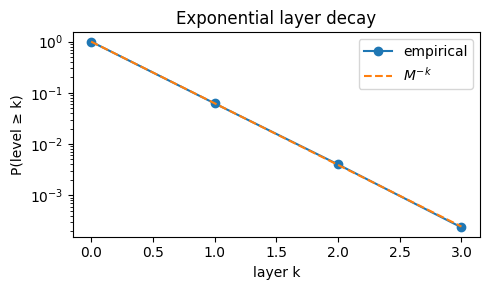

In [3]:
M = 16
idx = hnsw.HNSWIndex(dim=4, M=M, seed=1)
levels = np.array([idx._random_level() for _ in range(200_000)])
print(f"m_L = 1/ln({M}) = {idx.m_L:.4f}")
for k in range(4):
    print(f"P(level >= {k}) empirical {np.mean(levels >= k):.6f} | theory M^-{k} = {M**-k:.6f}")
fig, ax = plt.subplots(figsize=(5, 3))
ks = np.arange(4); emp = [np.mean(levels >= k) for k in ks]
ax.semilogy(ks, emp, "o-", label="empirical"); ax.semilogy(ks, [float(M)**-int(k) for k in ks], "--", label="$M^{-k}$")
ax.set_xlabel("layer k"); ax.set_ylabel("P(level ≥ k)"); ax.legend(); ax.set_title("Exponential layer decay"); plt.tight_layout(); plt.show()

### 3. Greedy skip-graph traversal — `search_layer(entry_point, query, ef, layer)`
Build a small index, then trace a query: greedy hops on the sparse upper layers, then a beam search of width `ef` on layer 0.

In [4]:
rng = np.random.default_rng(3)
data = hnsw.normalize_rows(rng.standard_normal((600, 32)))
small = hnsw.HNSWIndex(dim=32, M=8, ef_construction=64, seed=3)
small.add_batch(data)
print("layer sizes (layer 0 first):", small.layer_sizes(), "| entry point:", small.entry_point, "| max level:", small.max_level)
print("degree caps respected (M=8 upper, 2M=16 layer 0):", small.degree_stats())

q = hnsw.normalize_rows(rng.standard_normal(32))
ep = small.entry_point
print(f"\nquery descent from entry point {ep} (sim {float(small._vecs[ep] @ q):+.3f})")
for layer in range(small.max_level, 0, -1):
    nxt = small._greedy(ep, q, layer)
    print(f"  layer {layer}: node {ep} -> node {nxt}  (sim {float(small._vecs[nxt] @ q):+.3f})")
    ep = nxt
res = small.search_layer(ep, q, ef=10, layer=0)
print("layer 0 search_layer(ef=10), best 5:", [(n, round(s, 3)) for n, s in res[:5]])
exact = hnsw.flat_search(data, q, 5)
print("exact top-5            :", exact.tolist())
print("HNSW top-5             :", [i for i, _ in small.query(q, 5)])

layer sizes (layer 0 first): [600, 70, 10, 1] | entry point: 243 | max level: 3
degree caps respected (M=8 upper, 2M=16 layer 0): {'layer0_mean_deg': 12.926666666666666, 'layer0_max_deg': 16.0, 'layer1_mean_deg': 8.0, 'layer1_max_deg': 8.0, 'layer2_mean_deg': 8.0, 'layer2_max_deg': 8.0, 'layer3_mean_deg': 0.0, 'layer3_max_deg': 0.0}

query descent from entry point 243 (sim +0.058)
  layer 3: node 243 -> node 243  (sim +0.058)
  layer 2: node 243 -> node 422  (sim +0.288)
  layer 1: node 422 -> node 126  (sim +0.408)
layer 0 search_layer(ef=10), best 5: [(164, 0.408), (126, 0.408), (249, 0.383), (444, 0.361), (599, 0.349)]
exact top-5            : [323, 462, 552, 164, 126]
HNSW top-5             : [323, 462, 552, 164, 126]


### 4. Latency benchmark — HNSW vs brute-force flat search
$N=25{,}000$ unit vectors, $d=768$, 200 queries, top-10, $M=16$, `ef_construction=100`, `ef_search=64`. The data is a synthetic mixture of clusters with low-rank within-cluster spread (embedding-like); queries are fresh samples from the same mixture. Flat search is a single BLAS mat-vec over all $N$ rows. Timings are single-query latency, measured one query at a time on one CPU core.

The full run takes several minutes, so the notebook displays the results saved by `python 01_HNSW_Vector_Index.py` (`hnsw_benchmark_results.json`). Set `RERUN = True` to regenerate them here.

In [5]:
RERUN = False
path = pathlib.Path("hnsw_benchmark_results.json")
if RERUN or not path.exists():
    res = hnsw.run_benchmark(n=25000, dim=768, n_queries=200)
    path.write_text(json.dumps(res, indent=2))
res = json.loads(path.read_text())
c = res["config"]; print(c)
print(f"\n{'N':>7} {'flat ms':>9} {'HNSW ms':>9} {'speedup':>8} {'recall@10':>10} {'sim evals':>10} {'layers':>7}")
for r in res["scaling"]:
    print(f"{r['N']:>7,} {r['flat_ms']:>9.3f} {r['hnsw_ms']:>9.3f} {r['speedup']:>7.2f}x {r['recall_at_k']:>10.3f} {r['dist_evals']:>10.0f} {r['layers']:>7}")
print("\nlayer sizes:", res["layer_sizes"], "| build time (s):", round(res["build_seconds"], 1))

{'n': 25000, 'dim': 768, 'n_queries': 200, 'top_k': 10, 'M': 16, 'ef_construction': 100, 'ef_search': 64, 'seed': 42}

      N   flat ms   HNSW ms  speedup  recall@10  sim evals  layers
  1,000     0.150     0.712    0.21x      0.999        720       3
  2,500     0.359     0.861    0.42x      0.995       1014       3
  5,000     0.728     1.120    0.65x      0.987       1195       4
 10,000     1.315     1.138    1.16x      0.973       1328       4
 25,000     3.018     1.567    1.93x      0.945       1470       5

layer sizes: [25000, 1529, 101, 8, 1] | build time (s): 90.8


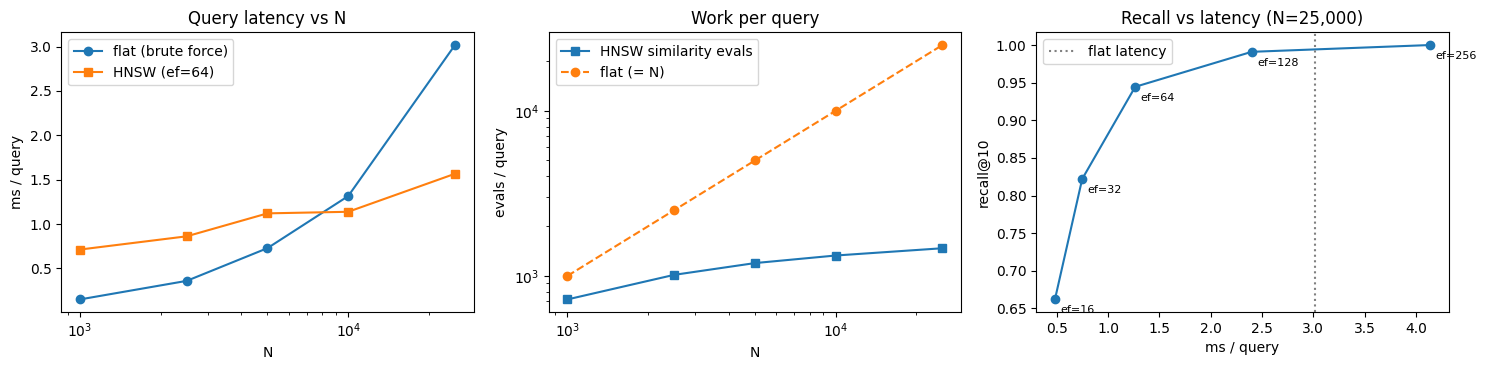

In [6]:
sc = res["scaling"]; N = [r["N"] for r in sc]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(N, [r["flat_ms"] for r in sc], "o-", label="flat (brute force)")
ax[0].plot(N, [r["hnsw_ms"] for r in sc], "s-", label="HNSW (ef=64)")
ax[0].set_xscale("log"); ax[0].set_xlabel("N"); ax[0].set_ylabel("ms / query"); ax[0].set_title("Query latency vs N"); ax[0].legend()
ax[1].plot(N, [r["dist_evals"] for r in sc], "s-", label="HNSW similarity evals")
ax[1].plot(N, N, "o--", label="flat (= N)"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("N"); ax[1].set_ylabel("evals / query"); ax[1].set_title("Work per query"); ax[1].legend()
sw = res["ef_sweep"]
ax[2].plot([s["hnsw_ms"] for s in sw], [s["recall_at_k"] for s in sw], "o-")
for s in sw: ax[2].annotate(f"ef={s['ef_search']}", (s["hnsw_ms"], s["recall_at_k"]), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax[2].axvline(sc[-1]["flat_ms"], color="gray", ls=":", label="flat latency"); ax[2].legend()
ax[2].set_xlabel("ms / query"); ax[2].set_ylabel("recall@10"); ax[2].set_title(f"Recall vs latency (N={c['n']:,})")
plt.tight_layout(); plt.show()

### 5. Full self-test suite

In [7]:
hnsw.run_self_tests()

USSE NOOSPHERE • SUBSYSTEM 05: HNSW VECTOR PROXIMITY INDEX — SELF-TESTS
[1] cosine core: scalar, zero-vector and vectorized forms agree
[2] layer assignment: P(l>=1)=0.0622 (theory 0.0625), P(l>=2)=0.00400 (theory 0.00391), m_L=0.3607


[3] small index (N=600): exact recall with ef=N; degree caps M=8/M0=16 respected; layers [600, 70, 10, 1]
[4] search_layer returns ef results sorted by similarity; best hit matches exact search


[5] same seed -> identical graph and results

[SUCCESS] HNSW self-tests passed.



### Findings
* **Logarithmic work, not linear.** Between N = 1,000 and N = 25,000 (25x more data) the similarity evaluations per query grow from about 720 to 1,470 (about 2x), while flat search must score all N vectors. At N = 25,000, HNSW scores about 5.9% of the corpus. The index has 5 layers (sizes 25,000 / 1,529 / 101 / 8 / 1), matching the $M^{-l}$ decay.
* **Wall-clock speedup is real but modest.** At N = 25,000, d = 768: HNSW 1.57 ms vs flat 3.02 ms per query (about 1.9x) at recall@10 = 0.945. Flat search is a single optimized BLAS mat-vec, and this HNSW is pure Python with per-hop overhead, so the crossover only comes near N of about 8,000 (at N = 1,000 flat is about 5x faster). Latency here is therefore around 1-2 ms, not sub-millisecond; ef = 32 gets 0.75 ms but only 0.82 recall.
* **Recall/latency trade-off is controlled by `ef_search`.** ef = 16 / 32 / 64 / 128 / 256 gives recall 0.66 / 0.82 / 0.95 / 0.99 / 1.00 at 0.48 / 0.75 / 1.27 / 2.40 / 4.14 ms. At ef = 128 recall is 0.99 and latency is still below flat search.
* **Caveats.** Single CPU core, one query at a time (batched flat search with a matrix-matrix product would be faster per query). Data is synthetic and clustered with low-rank spread; uniform random Gaussian vectors in 768 dimensions have almost no neighbour structure, and HNSW recall would be lower on them. Recall is measured against exact flat search on the same vectors.